# 基础物理 · 三自旋动力学与 Trotter 误差

QuantumBridge / 科学计算 / 中文可执行案例

**执行状态：仅本地运行；未提交夸父真机；新增云任务 0。**

面向了解 Python 的读者：完成建模、检查中间结果、运行原生电路或明确标记的经典密码步骤，并与独立基线核对。

**范围边界：** 仅三自旋模型与小规模全态基线，不声称大规模多体、核物理模拟或量子优势；本例一阶公式与参考资料中的其他阶数应分开看待。

## 1. 原理与计算对象

三自旋横场模型 $H=Z_0Z_1+Z_1Z_2+0.7\sum_iX_i$，初态 |100>，取 ħ=1。
精确基线用 8×8 矩阵谱分解计算 $e^{-itH}|100\rangle$。电路使用一阶乘积公式，按 ZZ 项后 X 项执行，每步 RZZ(2t/n)、RX(1.4t/n)。记录 n=1、4、12 的动力学。

比较 $\langle Z_0\rangle$、$\langle Z_0Z_2\rangle$ 及失真 $1-|\langle\psi_{exact}|\psi_n\rangle|^2$。有限步分裂误差与最后 1024 shots 的统计误差分别展示，不能相互抵消后宣称完全准确。

## 2. 实现步骤

1. 明确耦合、横场、初态与时间单位。
2. 生成精确谱演化及 13 个时间点的原生电路。
3. 比较 1/4/12 步的磁化和态失真。
4. 在 t=1.5、12 步电路独立采样磁化与关联函数。
5. 输出中间曲线、最终估计、标准误及 QASM。

## 3. 环境与可复现参数

依赖本仓库、NumPy、Matplotlib、Jupyter；安全案例还使用已安装的 OpenSSL / cryptography。模型和电路不调用 Qiskit 或 PennyLane。Notebook 保留真实执行输出，Python 解释器版本会在下方打印。

In [1]:
import os, sys, json
get_ipython().run_line_magic('matplotlib', 'inline')
from pathlib import Path
root = next((p for p in [Path(os.environ.get("QB_REPO_ROOT", ".")).resolve(), *Path.cwd().resolve().parents] if (p/"quantumbridge").is_dir() and (p/"scripts").is_dir()), None)
if root is None:
    raise RuntimeError("Run from the QuantumBridge checkout or set QB_REPO_ROOT.")
sys.path.insert(0, str(root)); sys.path.insert(0, str(root/"scripts"))
from IPython.display import display, HTML
from application_notebook_support import STYLE, show_json, intermediate_tables, plot_intermediate, show_measurements
from quantumbridge.applications.common import run_local_case
display(HTML(STYLE))
SHOTS, SEED = 1024, 20261023
print("Execution: LOCAL ONLY | cloud submissions: 0 | shots per circuit:", SHOTS)

print(sys.version)
import numpy as np
from quantumbridge.core import Circuit
from quantumbridge.devices import StatevectorDevice
from quantumbridge.chemistry import Molecule, molecular_hamiltonian_native
from quantumbridge.chemistry.excitations import apply_fermionic_excitation
from quantumbridge.chemistry.fermion import FermionicOp
from quantumbridge.chemistry.mappings import JordanWignerMapper
from quantumbridge.finance.kernels import labels, prepare_real_state
from quantumbridge.utils.math import PauliString
from quantumbridge.applications.common import ApplicationCase, optimization_case

Execution: LOCAL ONLY | cloud submissions: 0 | shots per circuit: 1024
3.12.6 (v3.12.6:a4a2d2b0d85, Sep  6 2024, 16:08:03) [Clang 13.0.0 (clang-1300.0.29.30)]


## 4. 完整应用建模代码

以下是本案例实际执行的应用函数，不是伪代码。底层电路、映射、演化与采样复用仓库原生接口；优化类的共享辅助函数也位于 `quantumbridge/applications/common.py`。

In [2]:
def dynamics_circuit(time, steps):
    circuit = Circuit(3, name="three-spin-trotter").x(0)
    for _ in range(steps):
        for left, right in ((0, 1), (1, 2)):
            circuit.rzz(2 * time / steps, left, right)
        for wire in range(3):
            circuit.rx(2 * 0.7 * time / steps, wire)
    return circuit


def physics_case():
    matrix = np.zeros((8, 8), complex)
    for pair in ((0, 1), (1, 2)):
        matrix += PauliString([(q, "Z") for q in pair]).matrix(3)
    for wire in range(3):
        matrix += 0.7 * PauliString([(wire, "X")]).matrix(3)
    energies, vectors = np.linalg.eigh(matrix)
    initial = np.eye(8)[:, 4]
    magnetization = np.array([(-1.0) ** int(bits[0]) for bits in labels(3)])
    correlation = np.array(
        [(-1.0) ** (int(bits[0]) + int(bits[2])) for bits in labels(3)]
    )
    table = []
    device = StatevectorDevice()
    for time in np.linspace(0, 1.5, 13):
        exact = vectors @ (np.exp(-1j * time * energies) * (vectors.conj().T @ initial))
        for steps in (1, 4, 12):
            approximation = device.statevector(dynamics_circuit(time, steps))
            table.append(
                {
                    "time": float(time),
                    "trotter_steps": steps,
                    "infidelity": max(
                        0.0, float(1 - abs(np.vdot(exact, approximation)) ** 2)
                    ),
                    "magnetization_z0": float(magnetization @ abs(approximation) ** 2),
                    "exact_z0": float(magnetization @ abs(exact) ** 2),
                    "correlation_z0z2": float(correlation @ abs(approximation) ** 2),
                }
            )
    return ApplicationCase(
        "physics",
        "science",
        "Three-spin Ising dynamics and Trotter error",
        {
            "J": 1.0,
            "transverse_field": 0.7,
            "initial_state": "100",
            "time_unit": "hbar/J",
            "measured_time": 1.5,
            "measured_steps": 12,
        },
        {"time_evolution": table, "spectrum": energies.tolist()},
        {
            "final_exact_z0": table[-1]["exact_z0"],
            "final_trotter_infidelity": table[-1]["infidelity"],
        },
        {
            "magnetization": dynamics_circuit(1.5, 12),
            "correlation": dynamics_circuit(1.5, 12),
        },
        {"magnetization": magnetization.tolist(), "correlation": correlation.tolist()},
    )


In [3]:
case = physics_case()
show_json(case.inputs)

## 5. 中间结果与效果

下方完整列出模型候选、优化轨迹或物理中间量。图中的 exact / classical 是经典计算基线，不冒充量子实验。图表使用英文坐标避免本机中文字体缺失，解释与表格保留中文。

time,trotter_steps,infidelity,magnetization_z0,exact_z0,correlation_z0z2
0,1,4.4408921e-16,-1,-1,-1
0,4,4.4408921e-16,-1,-1,-1
0,12,4.4408921e-16,-1,-1,-1
0.125,1,0.00023679736,-0.98472654,-0.98480588,-0.96968636
0.125,4,1.4730087e-05,-0.98480095,-0.98480588,-0.96983291
0.125,12,1.6362065e-06,-0.98480533,-0.98480588,-0.96984155
0.25,1,0.0036705675,-0.93937271,-0.94062274,-0.88242109
0.25,4,0.00022536498,-0.94054613,-0.94062274,-0.88462702
0.25,12,2.5011261e-05,-0.94061424,-0.94062274,-0.88475516
0.375,1,0.017589794,-0.86532394,-0.87149118,-0.74878552


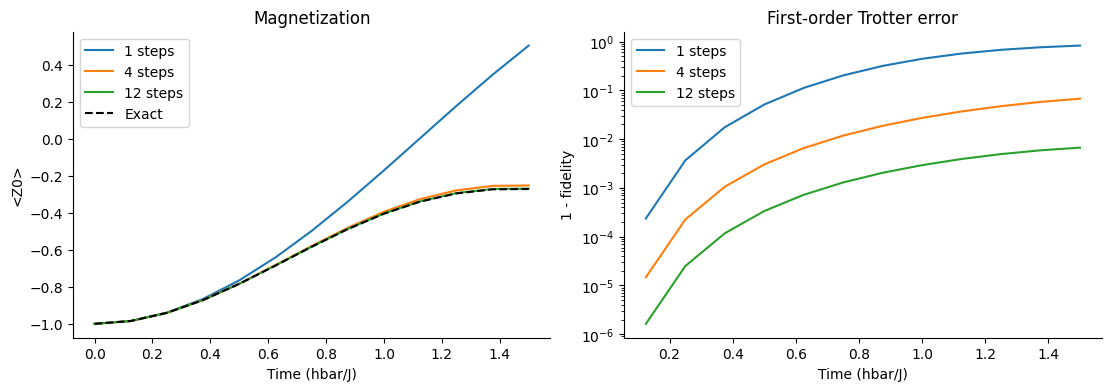

In [4]:
intermediate_tables(case)
plot_intermediate(case)

## 6. 实际运行与最终效果

模拟器使用固定种子逐次采样，counts 总数必须等于 shots。估计标准误由实际样本方差计算；近似 95% 区间可写作 estimate ± 1.96 × SE，但小样本及零计数需另用适当区间。本例不把这些区间当成硬件精度验收。

experiment,qubits,gates,shots,seed
magnetization,3,61,1024,20261023
correlation,3,61,1024,20261024


observable,estimate,standard_error,ideal_reference
magnetization,-0.2578125,0.030208347,-0.26876085
correlation,-0.1640625,0.030841624,-0.17045845


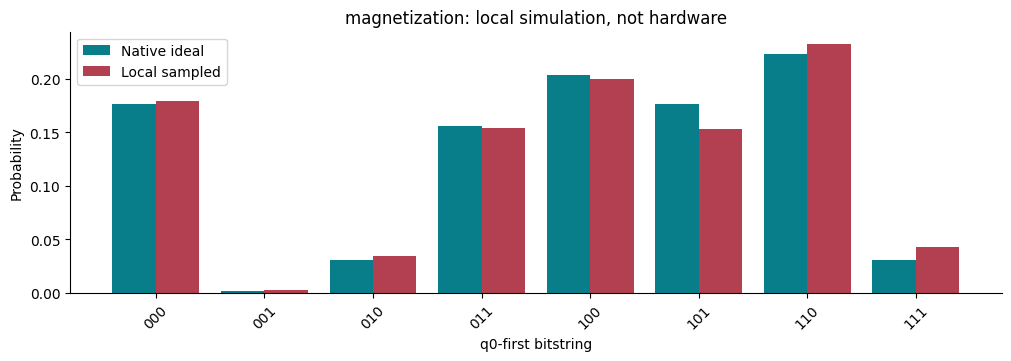

experiment,counts
magnetization,"{""011"": 158, ""101"": 157, ""110"": 238, ""000"": 184, ""010"": 35, ""100"": 205, ""111"": 44, ""001"": 3}"
correlation,"{""110"": 234, ""100"": 194, ""011"": 164, ""101"": 190, ""000"": 165, ""111"": 40, ""010"": 33, ""001"": 4}"


In [5]:
evidence = run_local_case(case, shots=SHOTS, seed=SEED)
show_measurements(case, evidence)

## 7. 可检查的电路输出

导出全部业务电路的 OpenQASM 2，位串采用 q0-first。可导出不等于已通过夸父设备门集、耦合图、深度和精度验收；本批不会访问凭据、提交任务或消耗金融额度。纯经典案例没有伪造量子电路。

In [6]:
for name, result in evidence['experiments'].items():
    print('\n---', name, '---\n'+result['openqasm2'])
if not evidence['experiments']:
    print('Classical cryptography / security workflow: no quantum circuit.')


--- magnetization ---
OPENQASM 2.0;
include "qelib1.inc";
qreg q[3];
creg c[3];
x q[0];
cx q[0],q[1];
rz(0.25) q[1];
cx q[0],q[1];
cx q[1],q[2];
rz(0.25) q[2];
cx q[1],q[2];
rx(0.17499999999999996) q[0];
rx(0.17499999999999996) q[1];
rx(0.17499999999999996) q[2];
cx q[0],q[1];
rz(0.25) q[1];
cx q[0],q[1];
cx q[1],q[2];
rz(0.25) q[2];
cx q[1],q[2];
rx(0.17499999999999996) q[0];
rx(0.17499999999999996) q[1];
rx(0.17499999999999996) q[2];
cx q[0],q[1];
rz(0.25) q[1];
cx q[0],q[1];
cx q[1],q[2];
rz(0.25) q[2];
cx q[1],q[2];
rx(0.17499999999999996) q[0];
rx(0.17499999999999996) q[1];
rx(0.17499999999999996) q[2];
cx q[0],q[1];
rz(0.25) q[1];
cx q[0],q[1];
cx q[1],q[2];
rz(0.25) q[2];
cx q[1],q[2];
rx(0.17499999999999996) q[0];
rx(0.17499999999999996) q[1];
rx(0.17499999999999996) q[2];
cx q[0],q[1];
rz(0.25) q[1];
cx q[0],q[1];
cx q[1],q[2];
rz(0.25) q[2];
cx q[1],q[2];
rx(0.17499999999999996) q[0];
rx(0.17499999999999996) q[1];
rx(0.17499999999999996) q[2];
cx q[0],q[1];
rz(0.25) q[1];
cx

## 8. 结果解释、复做与非目标

增加步数在本例减少末态分裂误差，但不改变给定 shots 的统计规律。先看 final_trotter_infidelity，再比较采样值与理想电路、精确演化两个基线。

仅三自旋模型与小规模全态基线，不声称大规模多体、核物理模拟或量子优势；本例一阶公式与参考资料中的其他阶数应分开看待。

练习：对已有电路将 shots 改为 2048，比较估计与标准误；如果是纯经典密码案例，比较密文/公钥大小和篡改检测结果。安全案例的私钥只在临时目录或内存中存在，不输出密钥。重新执行此 Notebook 仍然只运行本地代码。

In [7]:
repeat = run_local_case(case, shots=2048, seed=SEED+100)
show_json({'execution_mode':repeat['execution_mode'], 'estimates':repeat['estimates'], 'new_cloud_tasks':repeat['new_cloud_tasks']})
assert all(sum(row['counts'].values()) == 2048 for row in repeat['experiments'].values())
assert repeat['new_cloud_tasks'] == 0
assert repeat['hardware_access'] is False

In [8]:
artifact = {'inputs':case.inputs, 'intermediate':case.intermediate, 'reference':case.reference, 'evidence':evidence}
path = root/'output/jupyter-notebook/science/04_physics_evidence.json'
path.parent.mkdir(parents=True, exist_ok=True)
path.write_text(json.dumps(artifact, ensure_ascii=False, indent=2), encoding='utf-8')
print('Evidence:', path.name)

Evidence: 04_physics_evidence.json


## 9. 参考与责任边界

独立编写应用代码，未复制上游 SDK 实现或第三方教程代码；下列资料用于数学与接口背景。

- [IBM 时间演化与乘积公式](https://quantum.cloud.ibm.com/docs/en/tutorials/time-evolution)

本案例不是生产支持证书，也不代表 Qiskit / PennyLane 全量替代已经完成。